**Large Language Models**

_Copyright Notice_

This notebook is available for educational purposes. You may not use or distribute this notebook for commercial purposes. You may make copies of this notebook and use or distribute it for educational purposes as long as you cite the author as the source of the notebook.

Jaeyoung Chun | School of Applied Artificial Intelligence | Handong Global University

# Routing

## Load Environment Variables

In [1]:
from dotenv import load_dotenv

In [2]:
# retrieve API key and other environment variables
load_dotenv()

True

## Model

In [3]:
from langchain_openai import ChatOpenAI

In [4]:
model = ChatOpenAI(
    model_name="gpt-6-luna"
)

## State

In [5]:
from typing import Annotated, TypedDict

In [6]:
class State(TypedDict):
    review: str
    sentiment: str
    response: str

## Node

### Sentiment Analysis

In [7]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda
from langchain_core.output_parsers import StrOutputParser

In [8]:
prompt_sentiment = ChatPromptTemplate.from_messages(
    [
        (
            "system", "You are a helpful assistant.",
        ),
        (
            "human", "Classify the sentiment of this customer's product review as positive, negative, or neutral: {review}. You must answer either positive, negative, neutral, nothing else."
        )
    ]
)

In [9]:
task_lowercase = RunnableLambda(lambda text: text.lower())

In [10]:
task_sentiment = (
    prompt_sentiment
    | model
    | StrOutputParser()
    | task_lowercase
)

In [11]:
def node_sentiment_analysis(state: State):

    review = state["review"]

    sentiment = task_sentiment.invoke(review)

    return {
        "sentiment": sentiment
    }

### Writers

In [12]:
system_msg = "You are a customer representative who reads customer's review and respond to their product review."

In [13]:
def node_positive_writer(state: State):

    prompt = ChatPromptTemplate.from_messages(
        [
            (
                "system", system_msg,
            ),
            (
                "human", "Generate a thank-you note for this positive review: {review}."
            )
        ]
    )

    chain = (
        prompt
        | model
        | StrOutputParser()
    )

    result = chain.invoke(
        {
            "review": state["review"]
        }
    )

    return {
        "response": result
    }

In [14]:
def node_negative_writer(state: State):

    prompt = ChatPromptTemplate.from_messages(
        [
            (
                "system", system_msg,
            ),
            (
                "human", "Generate a response addressing this negative review: {review}. Ask if the customer wants a refund, a replacement, or something else."
            )
        ]
    )

    chain = (
        prompt
        | model
        | StrOutputParser()
    )

    result = chain.invoke(
        {
            "review": state["review"]
        }
    )

    return {
        "response": result
    }

In [15]:
def node_neutral_writer(state: State):

    prompt = ChatPromptTemplate.from_messages(
        [
            (
                "system", system_msg,
            ),
            (
                "human", "Generate a request for more details for this neutral review: {review}. Ask what needs to be done to make the product better."
            )
        ]
    )

    chain = (
        prompt
        | model
        | StrOutputParser()
    )

    result = chain.invoke(
        {
            "review": state["review"]
        }
    )

    return {
        "response": result
    }

## Conditional Edge

In [16]:
from typing import Literal

In [17]:
def which_writer(state: State) -> Literal["node_positive_writer", "node_negative_writer", "node_neutral_writer"]:

    sentiment = state["sentiment"]

    if sentiment == "positive":
        return "node_positive_writer"
    elif sentiment == "negative":
        return "node_negative_writer"
    elif sentiment == "neutral":
        return "node_neutral_writer"

## Build Graph

In [18]:
from langgraph.graph import StateGraph, START, END

In [19]:
graph = (
    StateGraph(State)

    # node
    .add_node("node_sentiment_analysis", node_sentiment_analysis)
    .add_node("node_positive_writer", node_positive_writer)
    .add_node("node_negative_writer", node_negative_writer)
    .add_node("node_neutral_writer", node_neutral_writer)

    # edge
    .add_edge(START, "node_sentiment_analysis")
    .add_conditional_edges("node_sentiment_analysis", which_writer)
    .add_edge("node_positive_writer", END)
    .add_edge("node_negative_writer", END)
    .add_edge("node_neutral_writer", END)    

    # compile
    .compile()
)

## Visualize Graph

Reference: https://langchain-ai.github.io/langgraph/how-tos/graph-api/#visualize-your-graph

In [20]:
from IPython.display import display, Image

In [21]:
diagram = Image(
    graph.get_graph().draw_mermaid_png()
)

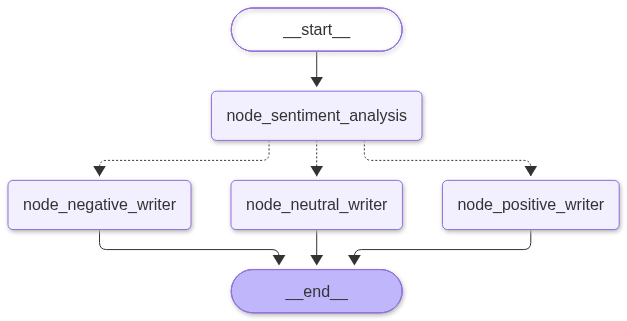

In [22]:
display(diagram)

## Run

### Positive Review

In [23]:
state = graph.invoke(
    {
        "review": "This product is really awesome!"
    }
)

In [24]:
state

{'review': 'This product is really awesome!',
 'sentiment': 'positive',
 'response': 'Thank you for the awesome review! We’re so glad you’re enjoying the product. 😊'}

In [25]:
print(state["response"])

Thank you for the awesome review! We’re so glad you’re enjoying the product. 😊


### Negative Review

In [26]:
state = graph.invoke(
    {
        "review": "This product no longer works after only one use!"
    }
)

In [27]:
state

{'review': 'This product no longer works after only one use!',
 'sentiment': 'negative',
 'response': 'We’re sorry the product stopped working after just one use—that’s not the experience we want you to have. Would you prefer a refund, a replacement, or another solution? Please contact us with your order details, and we’ll be happy to help.'}

In [28]:
print(state["response"])

We’re sorry the product stopped working after just one use—that’s not the experience we want you to have. Would you prefer a refund, a replacement, or another solution? Please contact us with your order details, and we’ll be happy to help.


### Neutral Review

In [29]:
state = graph.invoke(
    {
        "review": "This product does what it's supposed to do. Nothing more."
    }
)

In [30]:
state

{'review': "This product does what it's supposed to do. Nothing more.",
 'sentiment': 'neutral',
 'response': 'Thanks for sharing your feedback. What could we improve or add to make this product better for you?'}

In [31]:
print(state["response"])

Thanks for sharing your feedback. What could we improve or add to make this product better for you?
